# 3. Simulation-based calibration

SBC checks that a fitting procedure recovers the parameters that generated the data. We first run it on a model
with an exact posterior, so the mechanics are clear, and then show how multiplicity control changes a verdict.

In [1]:
import numpy as np

from symphony_dt.calibration import SBCDesign, judge, run_sbc


def generator(rng):
    mu, log_sigma = rng.normal(), rng.normal(0, 0.3)
    return rng.normal(mu, 1.0, size=12), {"mu": mu, "log_sigma_prior_draw": log_sigma}


def fitter(data, seed):
    rng = np.random.default_rng(seed)
    var = 1 / (1 + len(data))
    return {"mu": rng.normal(var * data.sum(), np.sqrt(var), size=400),
            "log_sigma_prior_draw": rng.normal(0, 0.3, size=400)}


result = run_sbc(SBCDesign(generator, fitter), n_replicates=300, seed=2)
result.verdict.to_dict()

{'method': 'bonferroni',
 'alpha': 0.01,
 'm': 2,
 'passed': True,
 'rejected': [],
 'fwer_uncorrected': 0.01990000000000003,
 'adjusted_threshold': {'log_sigma_prior_draw': 0.005, 'mu': 0.005},
 'p_values': {'log_sigma_prior_draw': 0.21194582365992848,
  'mu': 0.7990086941903265}}

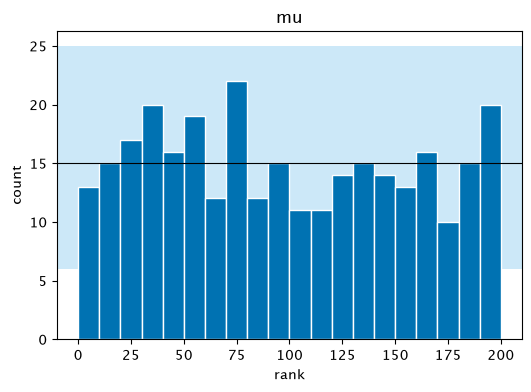

In [2]:
from symphony_dt.plots import plot_rank_histogram

plot_rank_histogram(result.ranks["mu"].to_numpy(), 199, title="mu");

## Judging many parameters

With many parameters, testing each at the 1% level without correction rejects a correct model often.

In [3]:
rng = np.random.default_rng(5)
p_values = {f"theta[{i}]": float(rng.uniform()) for i in range(55)}
for method in ("none", "bonferroni", "bh"):
    v = judge(p_values, method=method)
    print(method, "rejected:", len(v.rejected), "uncorrected family-wise risk:", round(v.fwer_uncorrected, 3))

none rejected: 1 uncorrected family-wise risk: 0.425
bonferroni rejected: 0 uncorrected family-wise risk: 0.425
bh rejected: 0 uncorrected family-wise risk: 0.425


## SBC for pd_v2

`pd_v2_prior_design` builds a prior-regime design for pd_v2. Each replicate is a full Stan fit, so a campaign
runs on a cluster. From the command line: `symphony-dt sbc --replicates 200 --n 60`.